# Демонстрация создания опроса

Тетрадь дает общее представление и пример запуска скрипта создания опроса.

Для запуска необходимо указать реальные `login` / `password` или воспользоваться `.env` файлом

In [ ]:
# Мантра для разработчика
%load_ext autoreload
%autoreload 2

# Основная библиотека для взаимодействия с API конструктора опросов.
import socapi as soc

# Библиотека, которая подгружает данные из .env файла, если таковой существует рядом с файлом тетради
from dotenv import load_dotenv
load_dotenv()

# Библиотека, отвечающая за корректное использование данных из .env файла
import os

# Сохраняем данные для входа в конструктор опросов из .env файла
login=os.getenv("LOGIN", "")
password= os.getenv("PASSWORD", "")

# Настраиваем глобальные переменные

Они будут автоматически подставляться в формулировки вопросов и ответов, где это надо

In [ ]:
my_region = 'Москва'
in_my_region = 'в Москве'

## Проверяем подключение

Прежде чем начать создавать опросы, надо проверить, что система работает корректно и даст нам залогиниться.

Проверим, что мы, это мы - создадим подключение и запросим у системы данные нашего аккаунта.

В переменную `me` будут сохранены данные нашей учетки

In [ ]:
async with (soc.ParserClient(login=login, password=password, host="online-sociology.ru") as client):
    me = await client.user.profile()

## Создание опроса

На примере анкеты `Общая выборка РКЖ 2025` попробуем запрограммировать опрос и изучить основные фичи

Для начала создадим сущность опроса. В нашей библиотеке за него отвечает класс `Poll`.
В нем хранится основная информация об опросе - название, уровни доступа, география.
Создавая опрос, мы должны записать всю ту информацию, что указываем в web-интерфейсе при создании опроса (см. скриншот)

<details>
<summary>Скриншот формы создания опроса</summary>

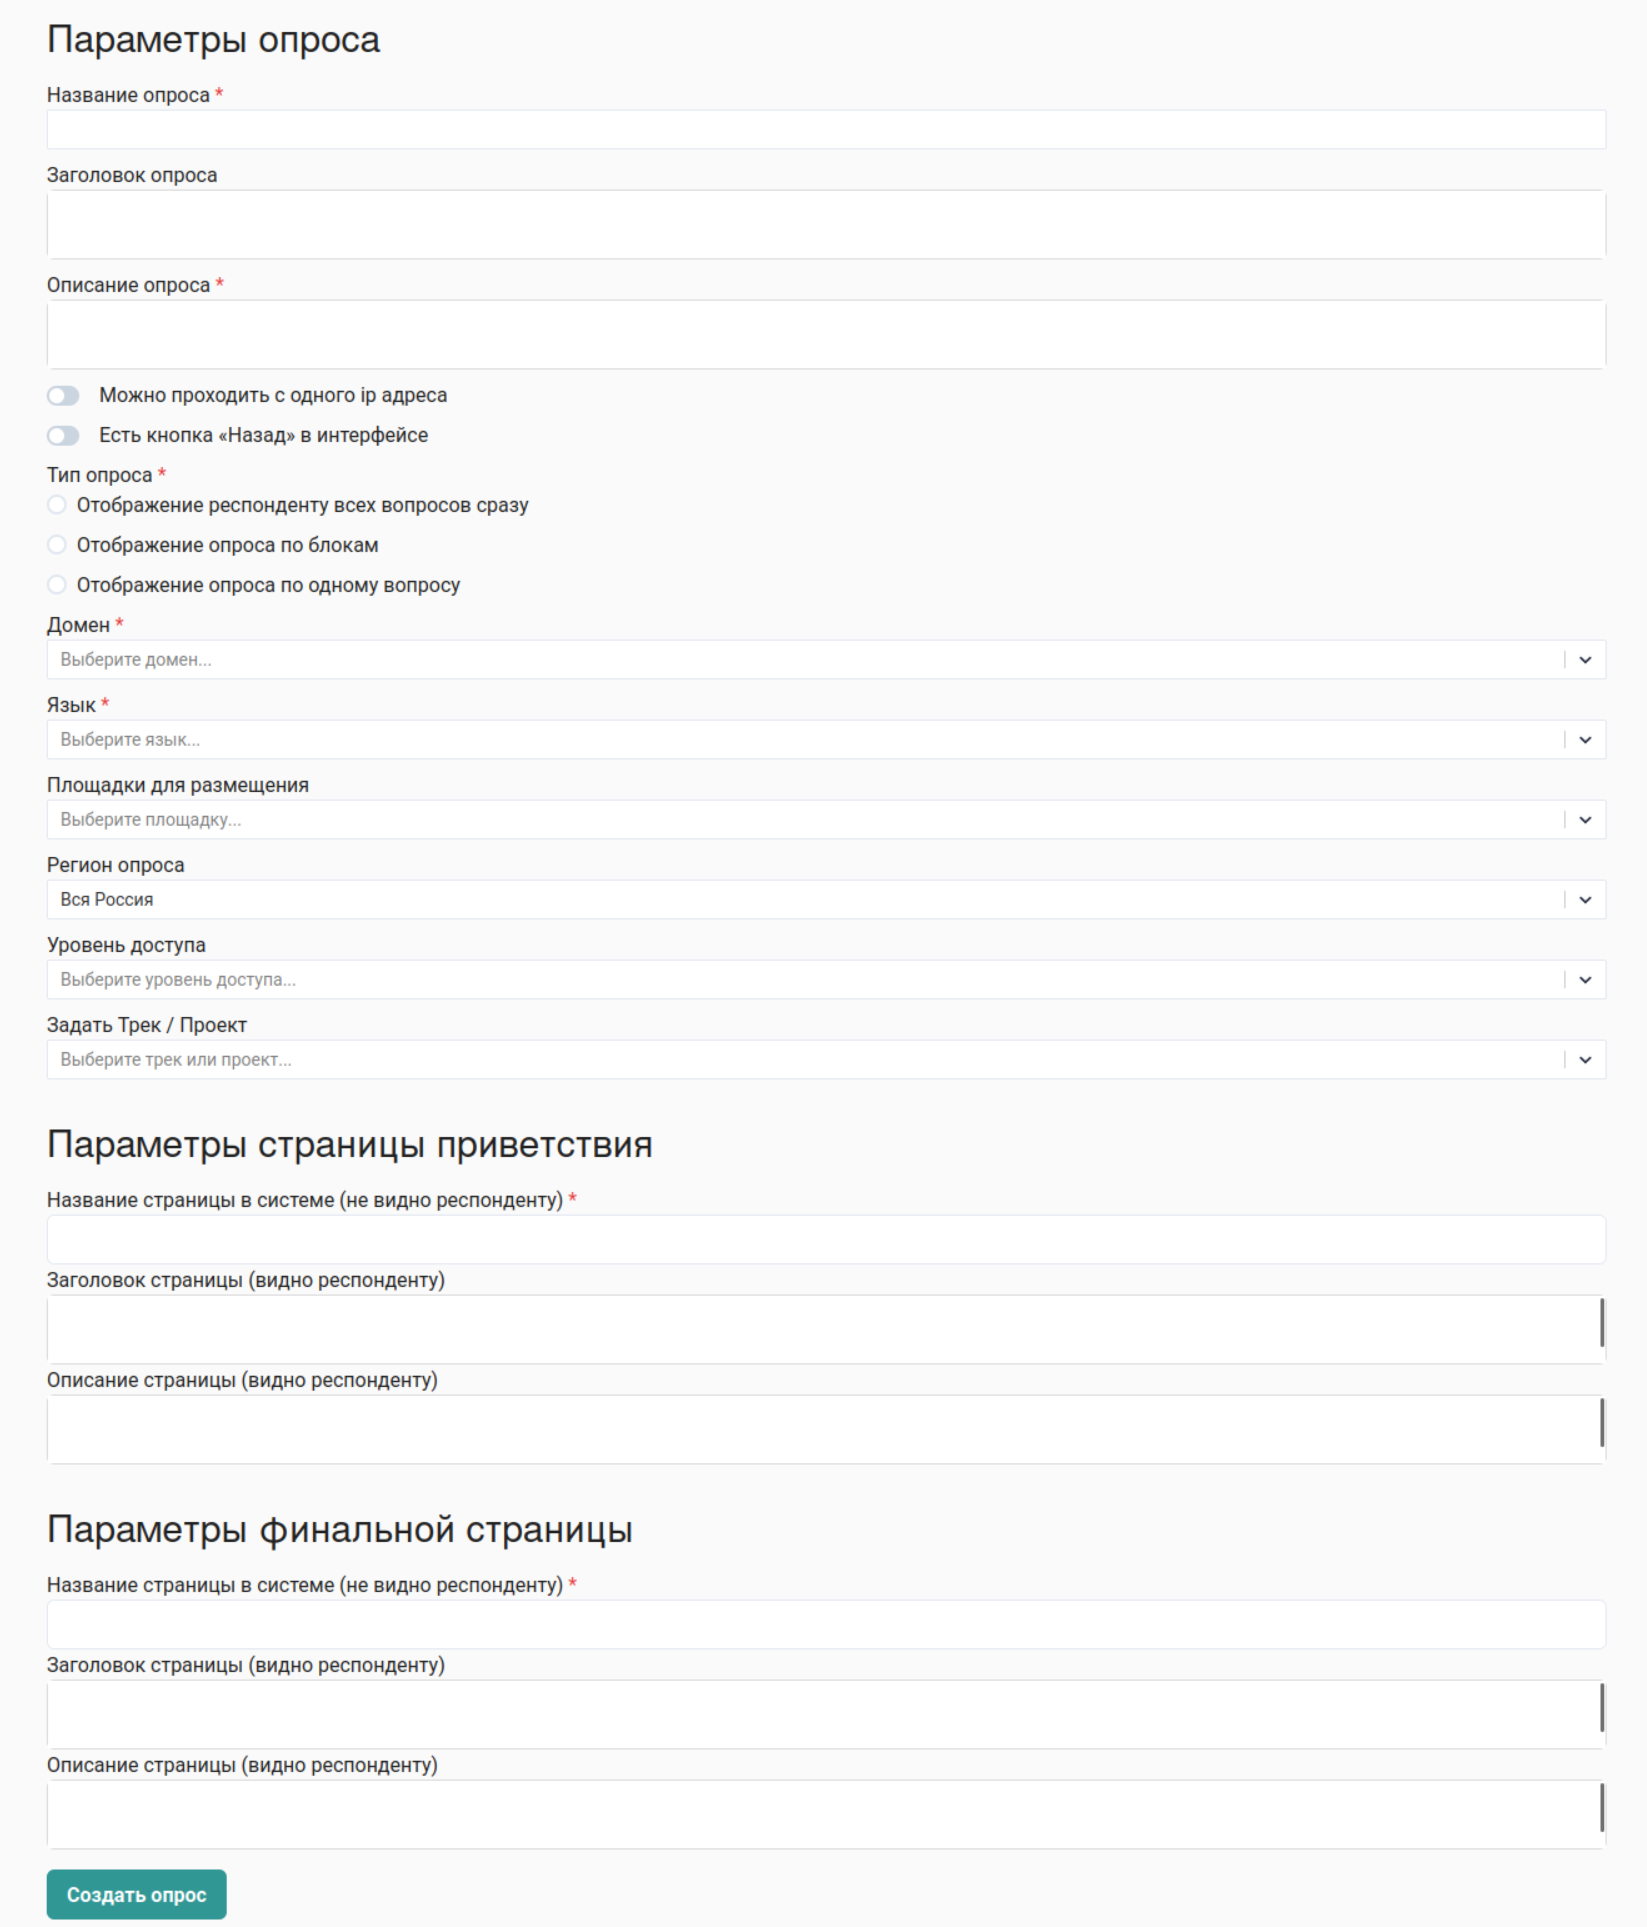

</details>
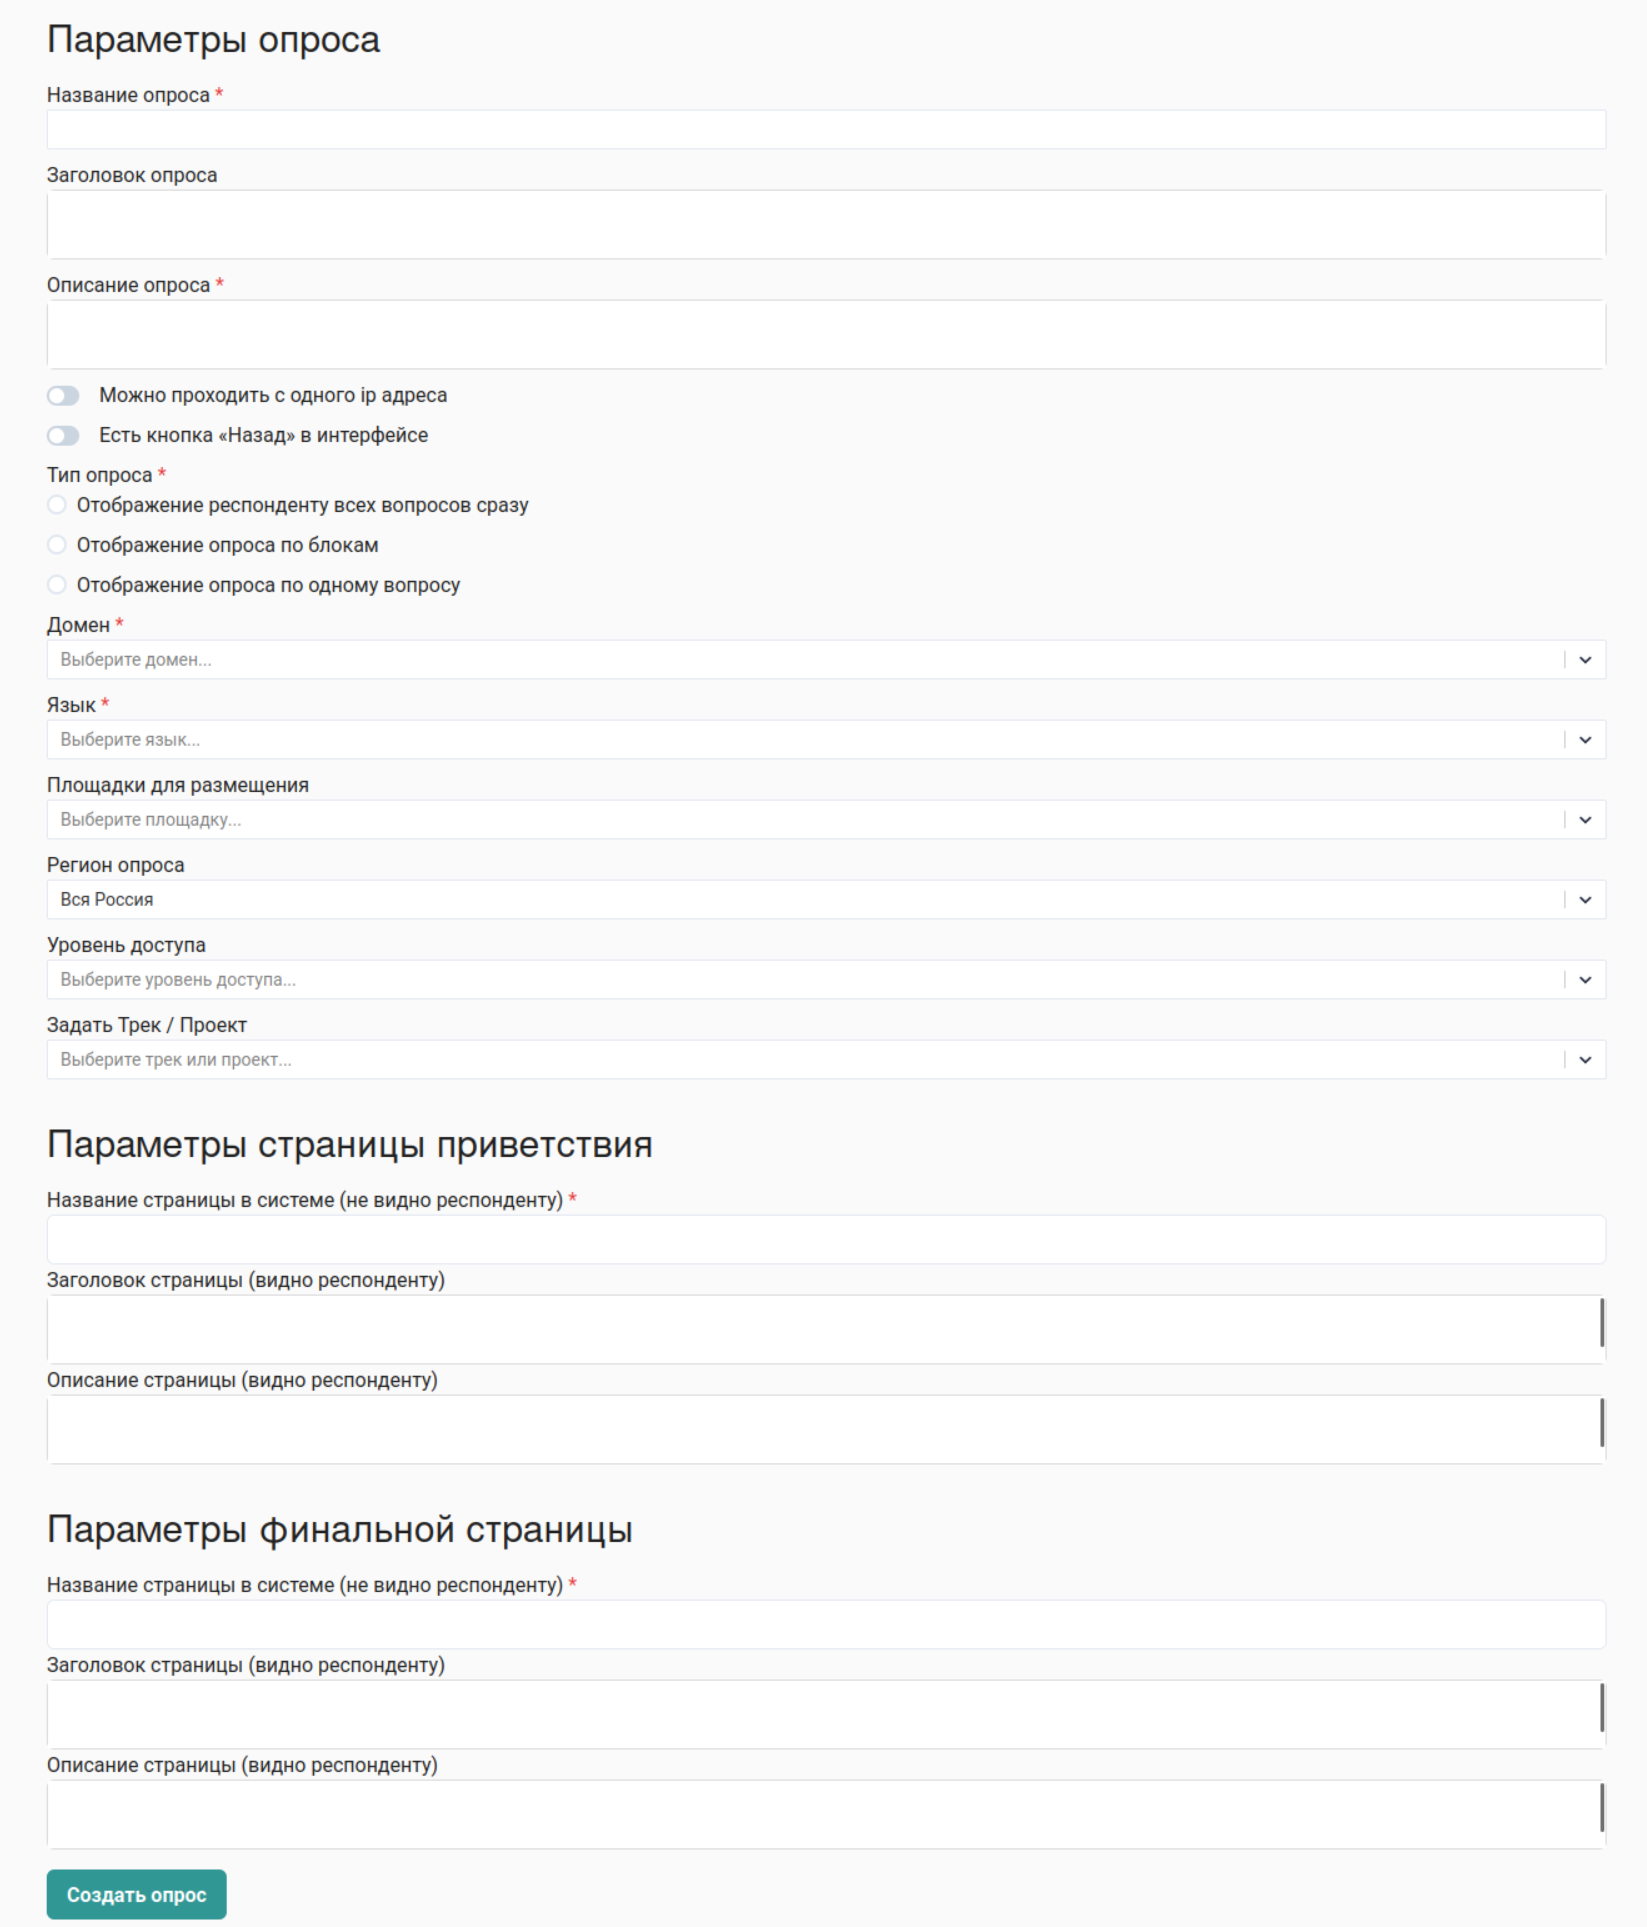
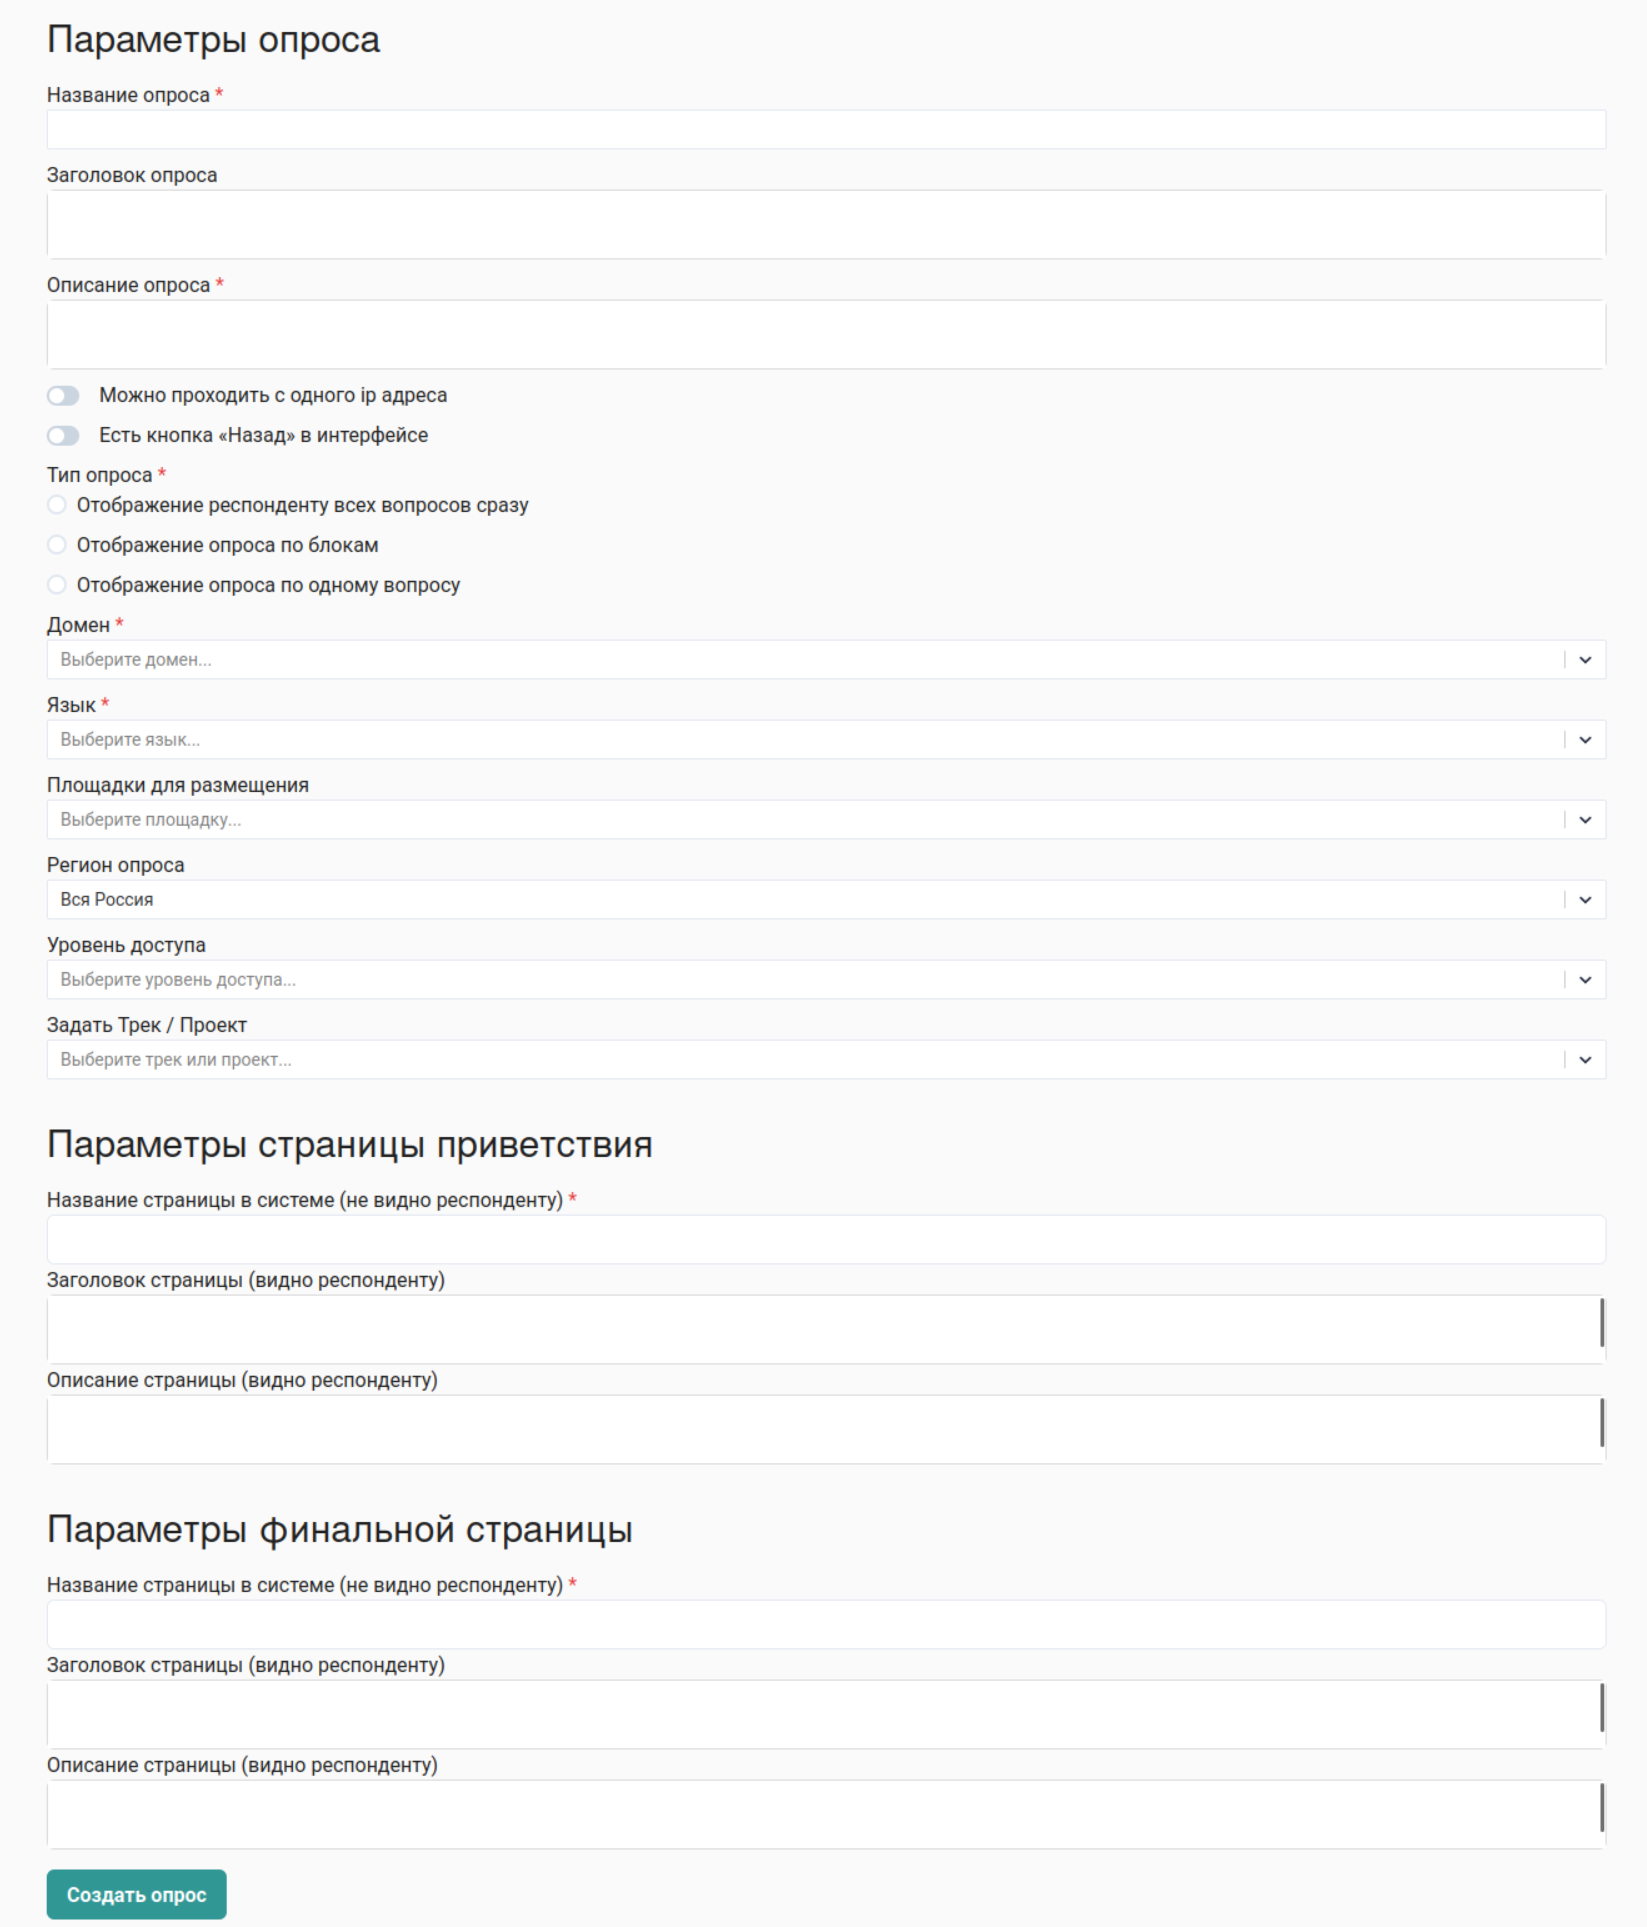
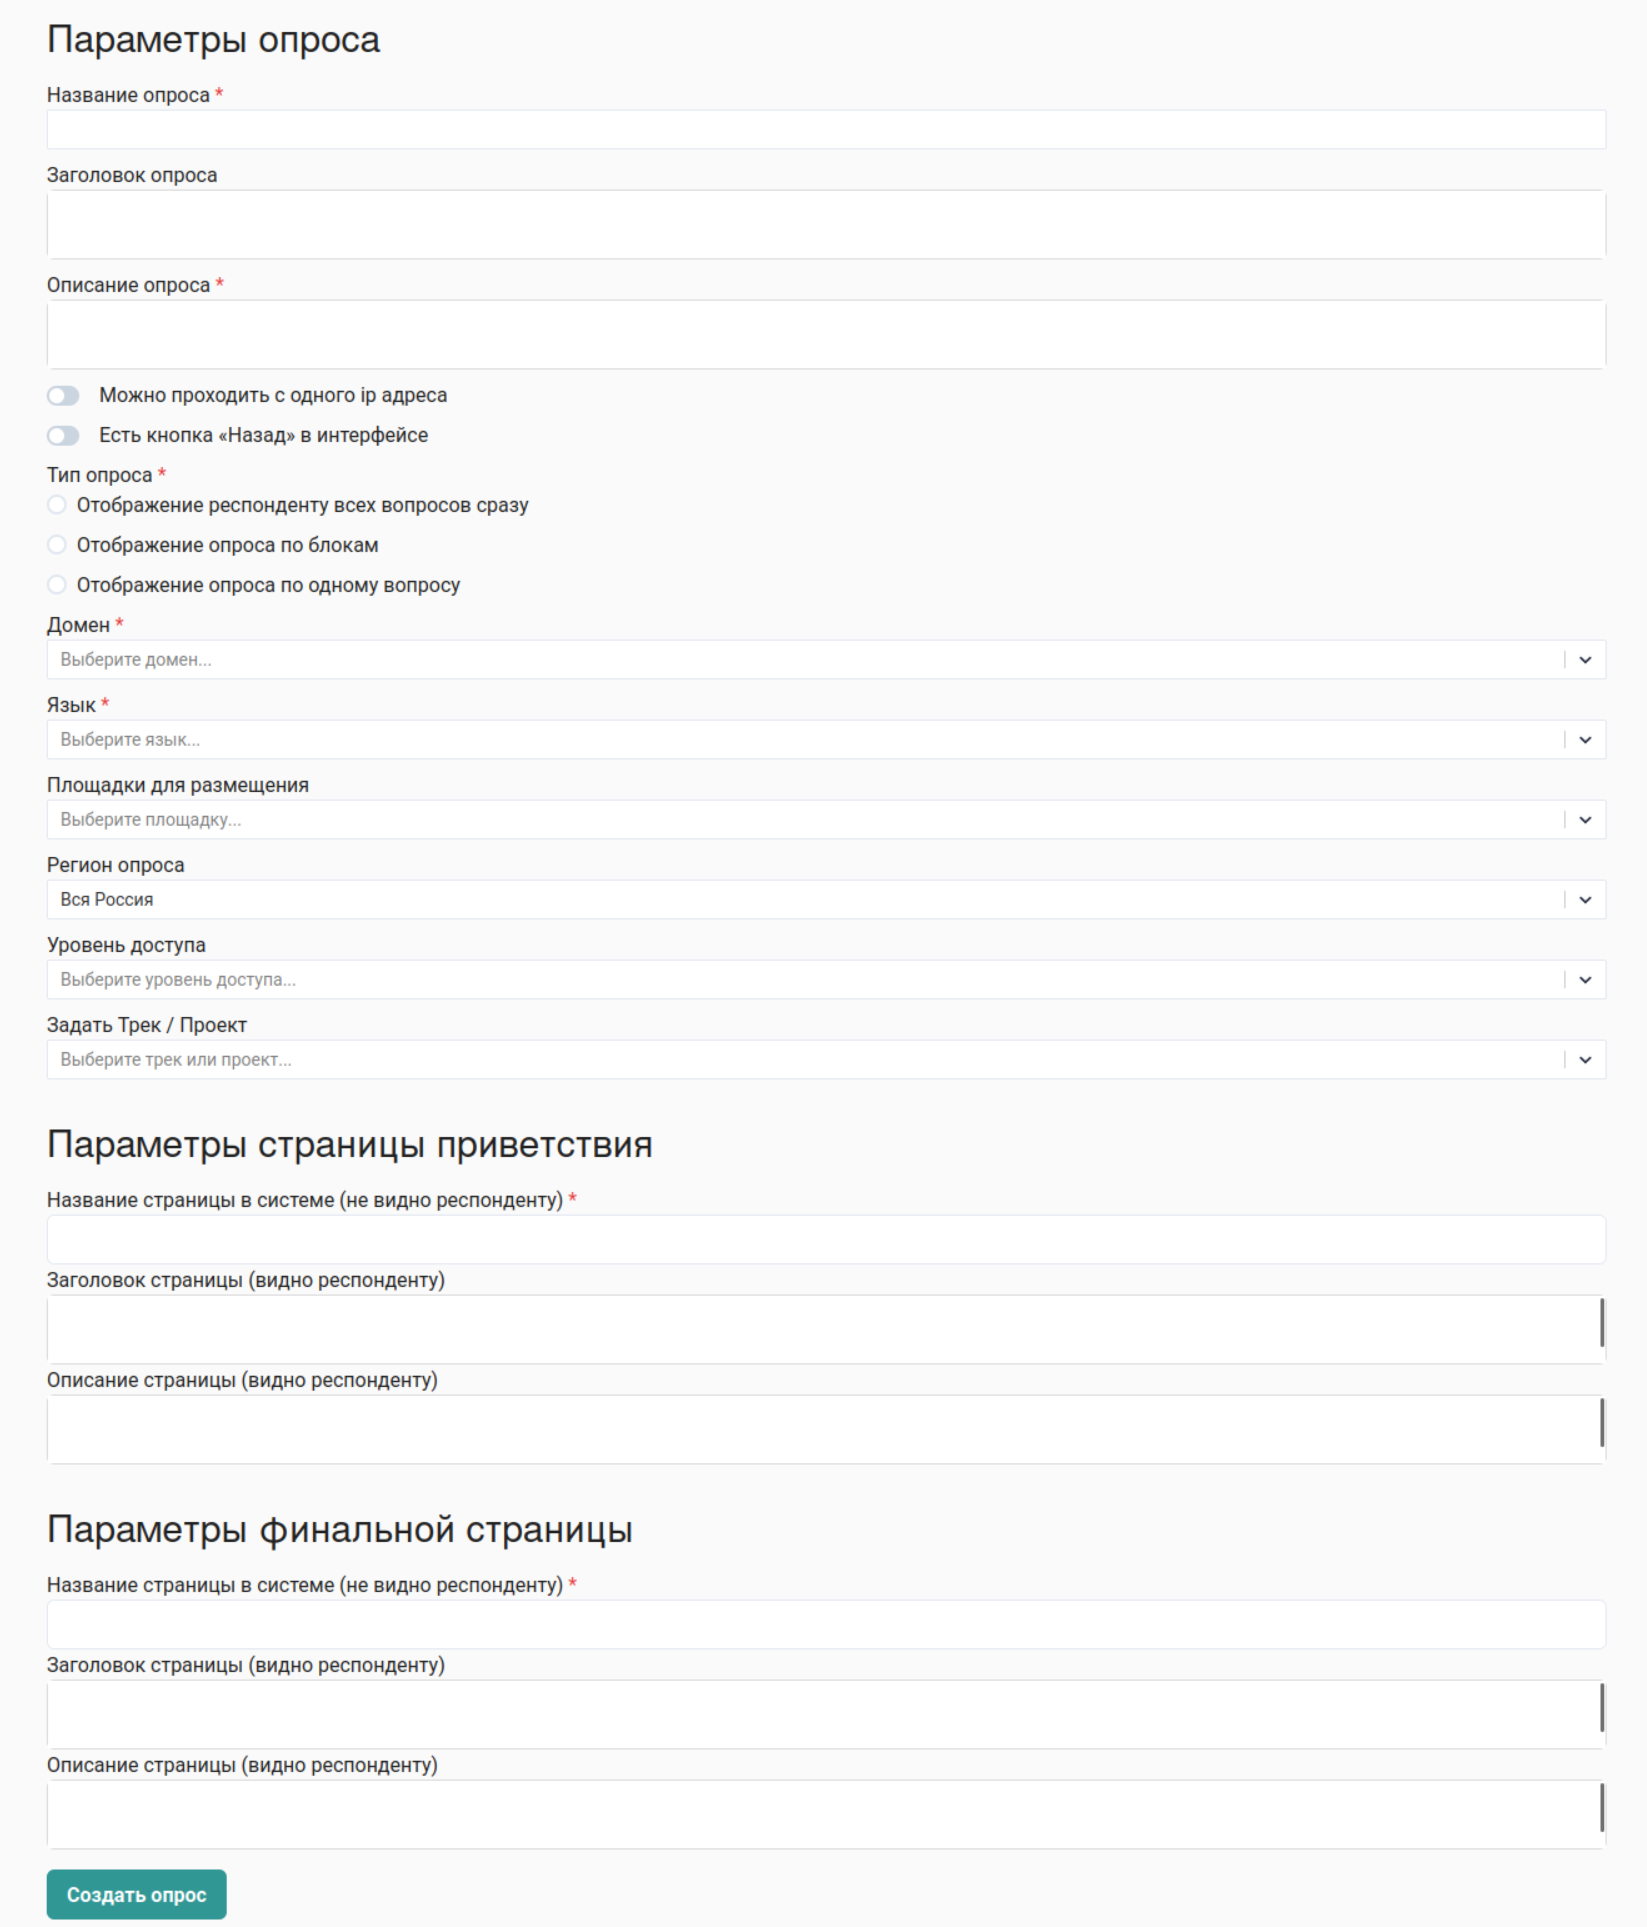
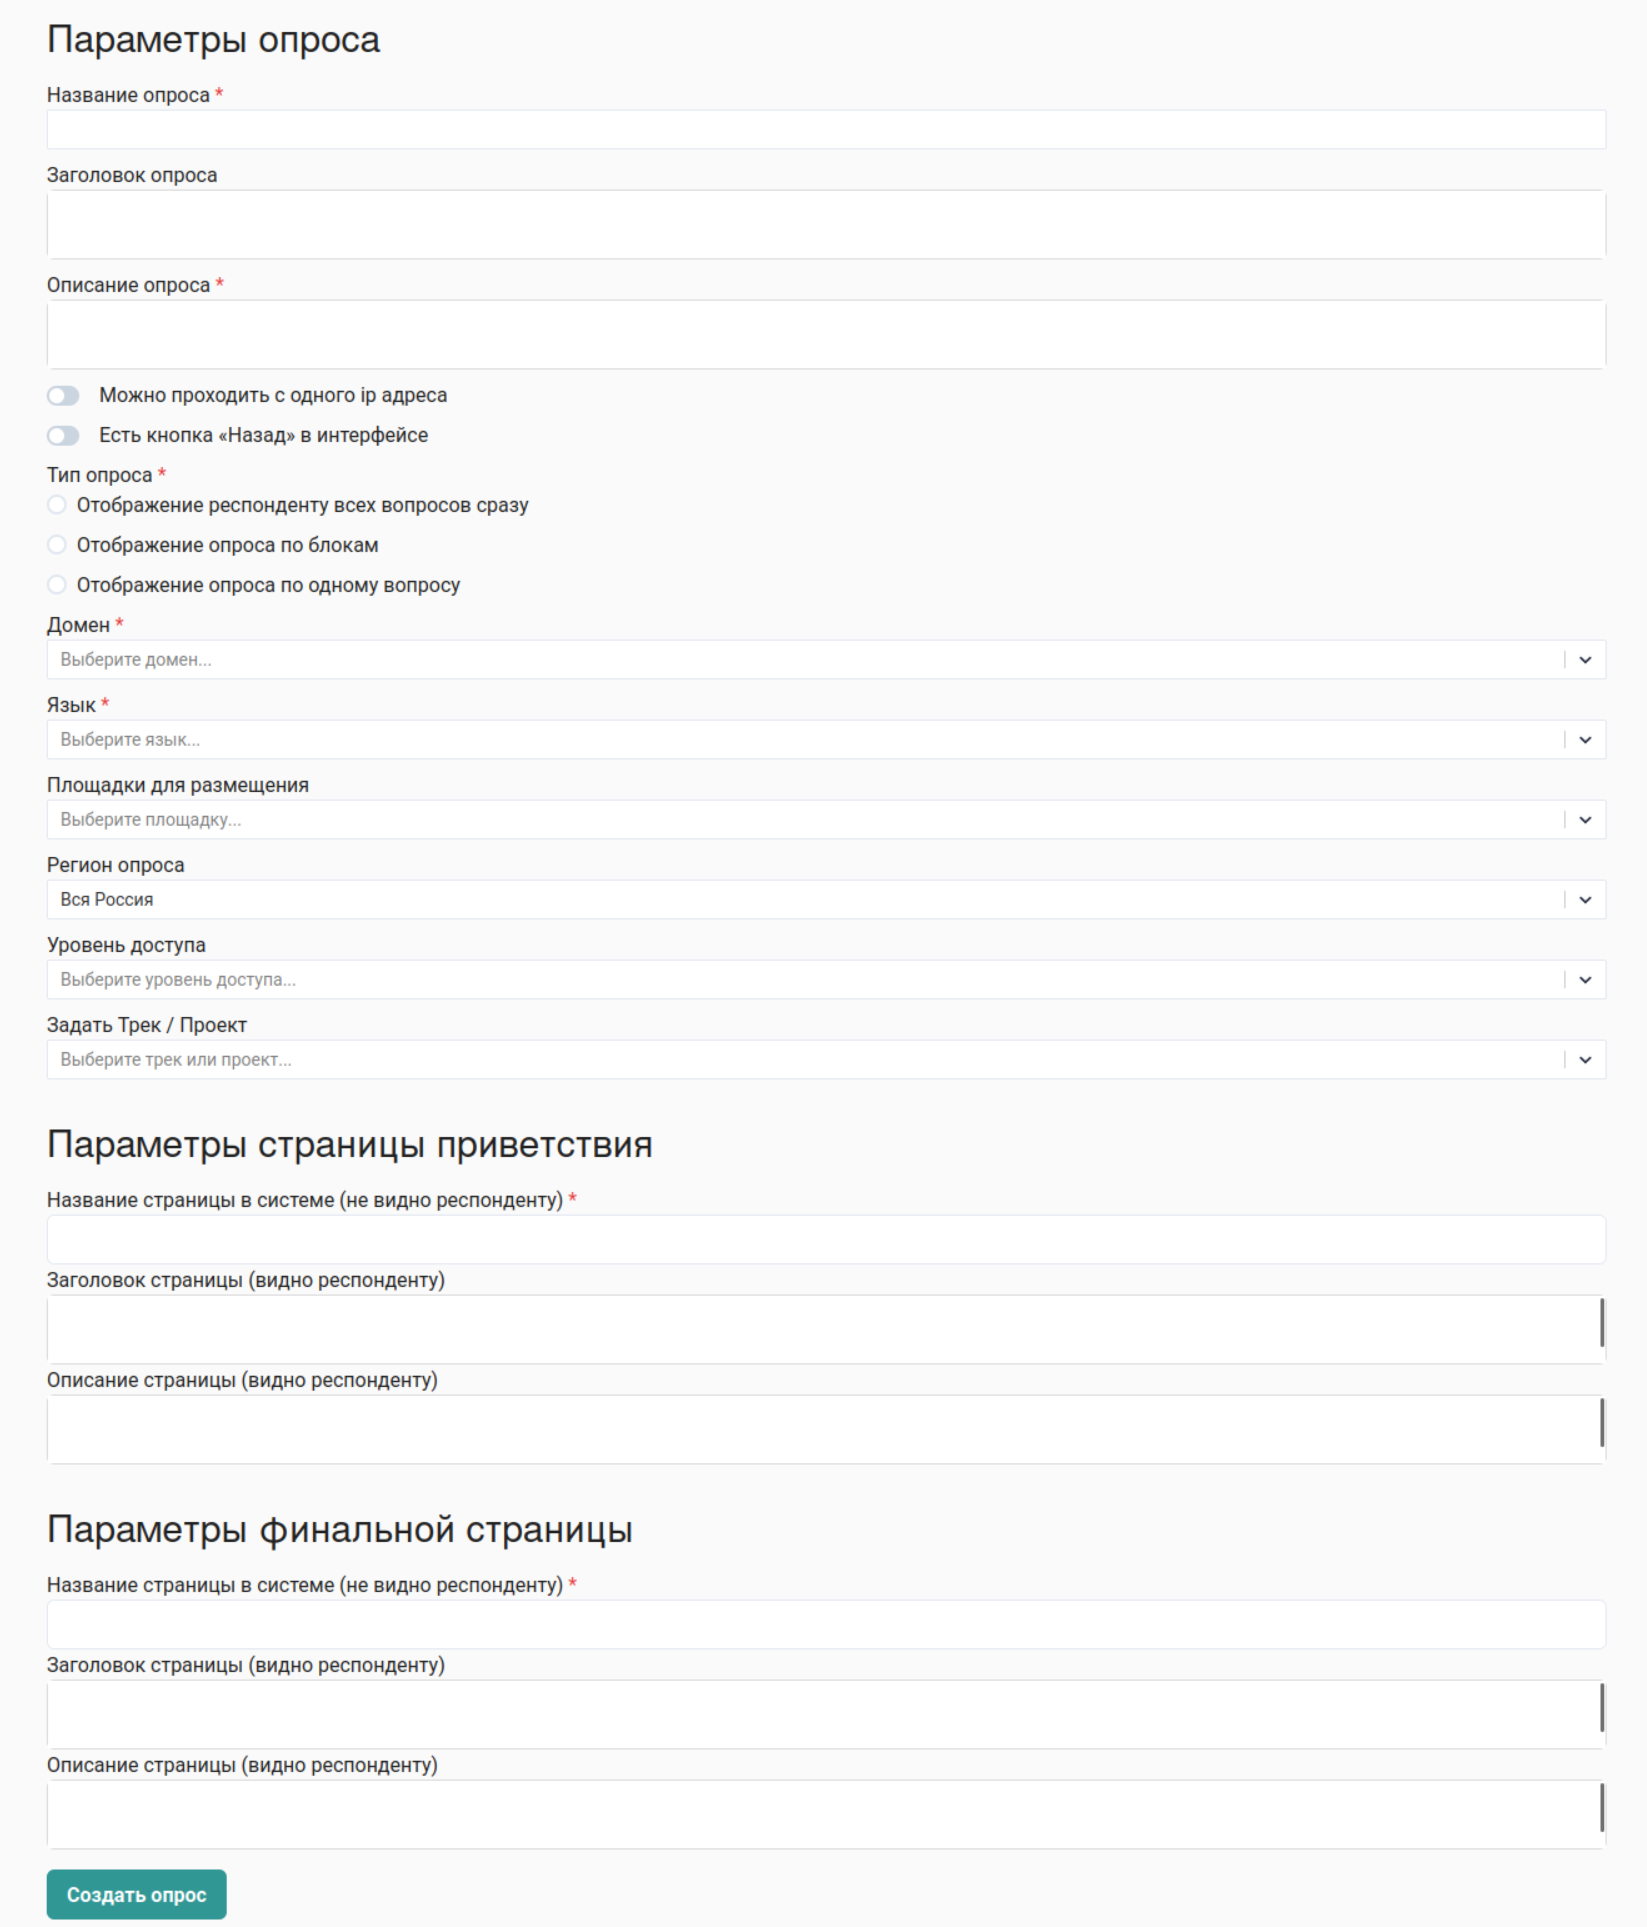

In [ ]:
poll = soc.Poll(
    name=f'--ТЕСТ АВТО ОПРОСА-- Анкета. Общая выборка - {my_region}', # Название опроса - то, как опрос будет отображаться в системе
    description="Тест создания автоопроса на примере анкеты Общей выборки РКЖ 2025",
    title="Заголовок", # Заголовок опроса - необязательное поле
    type_id="one_question",  # Тип опроса
    user_id=me.id, # поставим себя как автора опроса
    meta=[0], # пока так вот
    is_multiple=True, # Можно заходить повторно
    can_cameback=False, # Есть кнопка "назад"
)

## Добавление страниц

Создадим стартовую, финальную и дисквалификационные страницы

Для этого у нашего опроса `poll` есть метод `.add_page()`, позволяющий "прицепить" к нему страницу.

Создать страницу можно двумя способами:
1) Передав в `.add_page()` последовательно аргументы, необходимые для создания страницы (как мы это делали с опросом выше)
2) Передав в `.add_page()` страницу целиком, создав сначала сущность `Page`.

В любом случае метод `.add_page()` вернет нам свеже созданную страницу, соответствующую нашим параметрам

<details>
<summary>Скриншот формы создания страницы</summary>

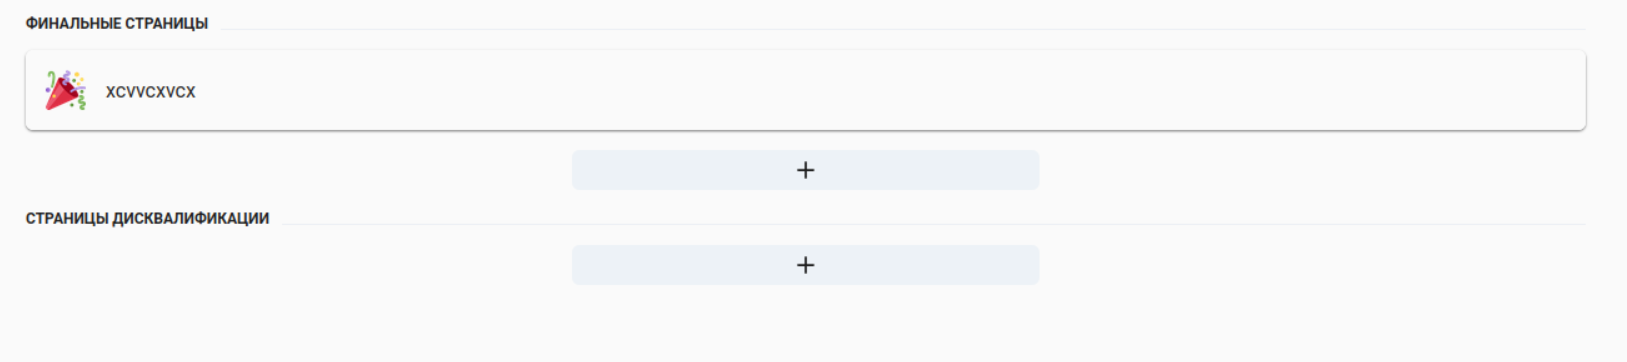!

</details>

In [ ]:
# Первый способ - передаем аргументы по одному.
start_page = poll.add_page(
    name="Стартовая страница",
    type_id='greeting',
    title="Заголовок",
    description="Здравствуйте! Это исследование проводится с целью определения ключевых зон роста и решений по "
                "повышению качества жизни граждан в субъектах Российской Федерации. "
                "Просим Вас ответить на вопросы о населенном пункте и регионе Вашего проживания. "
                "Прохождение анкеты займет примерно 15-20 минут.\n"
                'Мы гарантируем анонимность и конфиденциальность Ваших ответов, '
                'анализируем данные только в обобщенном виде.'
)

# Второй способ - сначала создаем шаблон страницы, потом цепляем к опросу
finish_page = soc.Page(
    name="Финальная страница",
    type_id='finish',
    data=soc.PageData(
        title= "Завершающая страница",
        description = "Спасибо за участие в опросе! ❤️",
    )
)
finish_page = poll.add_page(finish_page)


disqualified_page = poll.add_page(
    name="Страница дисквалицификации",
    type_id='disqualification',
    title="Заголовок",
    description="Спасибо за участие в опросе! Но больше не приходите 💔"
)

## Добавление блока

Опрос состоит из блоков.
Прежде чем начать создавать вопросы, нужно создать под них блок.

<details>
<summary>Скриншот формы создания блока</summary>

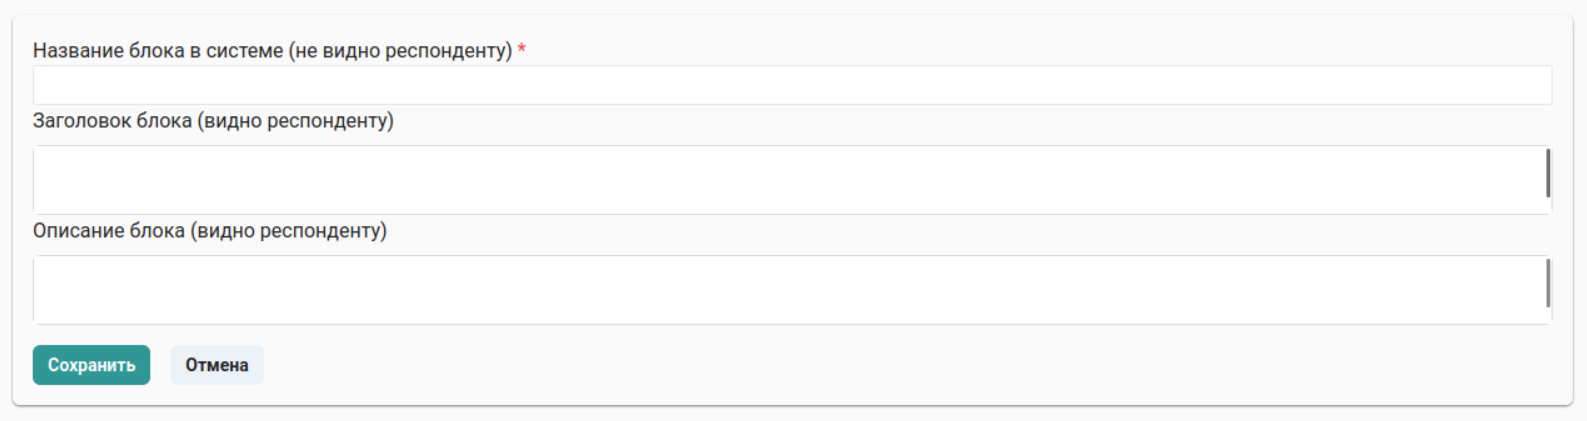

</details>
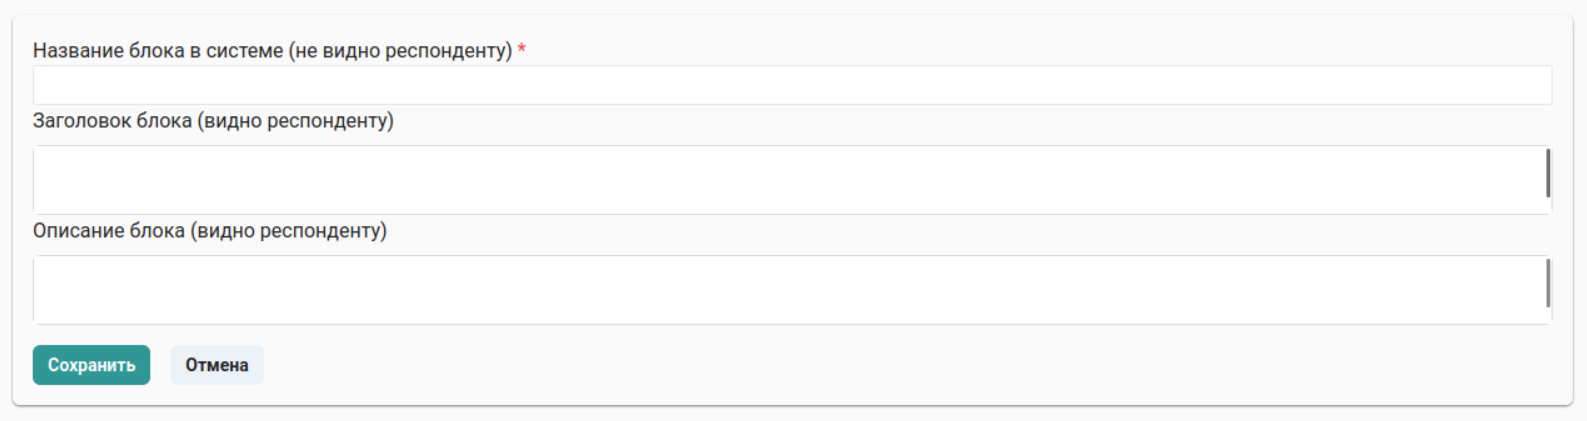
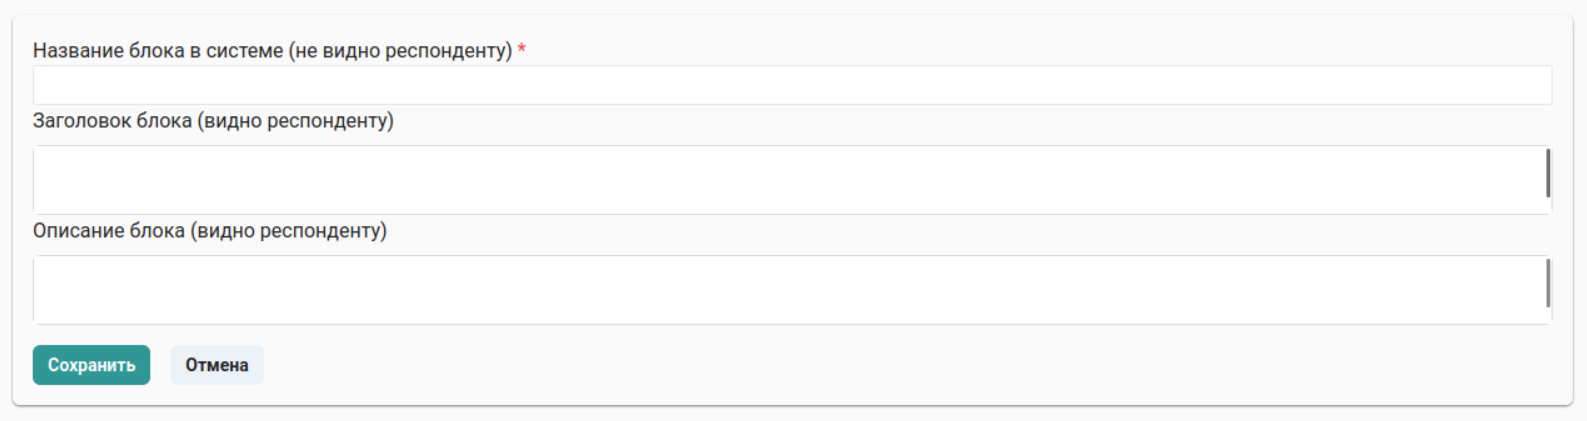

In [ ]:
intro_block = poll.add_block(
    name='1 - ВВОДНЫЙ БЛОК',
    title='Коротко о Вас',
    description="Давайте соберем о вас персональные данные. Обещаем никуда их не продавать 🙏"
)

## Создание вопросов

Последовательно создаем вопросы.
Чтобы создать логику, все вопросы и страницы, которые в ней задействованы, должны быть созданы.

### Информационный экран

In [ ]:
first_info_screen = intro_block.add_question(
    title='**Чтобы помочь классифицировать ответы и сделать их статистически сопоставимыми, просим ответить на несколько вопросов о Вас.**',
    type_id='info_material',
)

### Одноответный вопрос

In [ ]:
# Добавим информационный экран
age = intro_block.add_question(
    title='**Сколько Вам полных лет?**',
    type_id='single_answer',
    answers=[
        'До 16 лет',
        soc.Answer(title="16-24", has_input=True, input_validation='number'),
        soc.Answer(title="25-59", has_input=True, input_validation='number'),
        soc.Answer(title='60 лет и старше (укажите)', has_input=True, input_validation='number'),
    ],
)

### Логика перехода на страницу дисквалификации

In [ ]:
age_filter = age.add_jump(
    target=disqualified_page,
    comparator='is_selected',
    reference_answer_order=1
)

### Вопрос с логикой отображения

In [ ]:
gender = intro_block.add_question(
    title="Укажите ваш пол",
    type_id='single_answer',
    answers=['Мужской', 'Женский'],
)
display_gender = gender.add_display(
    reference_question=age,
    comparator='is_not_selected',
    reference_answer_order=1,
)

### Множественный вопрос

In [ ]:
migration_reasons = intro_block.add_question(
    title='**Есть ли у Вас опыт переезда в другой регион или нет опыта? Если есть, регион, куда Вы переехали – это регион, в котором Вы сейчас проживаете?**',
    type_id='multiple_choice',
    randomized=True,
    max_answer=5,
    answers=[
        'another answer',
        migration_edu:=soc.Answer(title='В связи с получением образования'),
        migration_work:=soc.Answer(title='В связи с трудоустройством'),
        'В связи с трудоустройством',
        'В связи с женитьбой / замужеством',
        'В связи с переездом моей семьи',
        'В связи с лечением, прохождением реабилитации',
        'В регионе отъезда недостаточно возможностей для самореализации, развития',
        'В регионе отъезда было недостаточно возможностей для построения и развития своей семьи',
        'В регионе отъезда было недостаточно возможностей для открытия и ведения собственного бизнеса ',
        'В регионе отъезда не было возможностей для приобретения собственного жилья, съема жилья',
        'В регионе отъезда не устраивали доступность и качество медицинских услуг ',
        'В регионе отъезда было недостаточно возможностей для занятий спортом, проведения досуга, свободного времени, развлечений',
        'В регионе отъезда были неразвитые инфраструктура, общественные пространства, парки, дороги',
        'В регионе отъезда не устраивала экологическая ситуация ',
        'В регионе отъезда низкий уровень безопасности ',
        soc.Answer(title='Ни одно из вышеперечисленного', exclude_answer=True, skip_randomize=True)
            ]
)

In [ ]:
migration_destination = intro_block.add_question(
    title="**Из какого региона Вы переехали в связи с трудоустройством / получением образования?**",
    type_id='single_answer',
    answers=[
        'Москва',
        'Санкт-Петербург',
        'Севастополь',
        'Алтайский край',
        'Амурская область',
        'Архангельская область',
        'Астраханская область',
        'Белгородская область',
        'Брянская область',
        'Владимирская область',
        'Волгоградская область',
        'Вологодская область',
        'Воронежская область',
        'Еврейская автономная область',
        'Забайкальский край',
        'Ивановская область',
        'Иркутская область',
        'Кабардино-Балкарская Республика',
        'Калининградская область',
        'Калужская область',
        'Камчатский край',
        'Карачаево-Черкесская Республика',
        'Кемеровская область – Кузбасс',
        'Кировская область',
        'Костромская область',
        'Краснодарский край',
        'Красноярский край',
        'Курганская область',
        'Курская область',
        'Ленинградская область',
        'Липецкая область',
        'Магаданская область',
        'Московская область',
        'Мурманская область',
        'Ненецкий автономный округ',
        'Нижегородская область',
        'Новгородская область',
        'Новосибирская область',
        'Омская область',
        'Оренбургская область',
        'Орловская область',
        'Пензенская область',
        'Пермский край',
        'Приморский край',
        'Псковская область',
        'Республика Адыгея ',
        'Республика Алтай',
        'Республика Башкортостан',
        'Республика Бурятия',
        'Республика Дагестан',
        'Республика Ингушетия',
        'Республика Калмыкия',
        'Республика Карелия',
        'Республика Коми',
        'Республика Крым',
        'Республика Марий Эл',
        'Республика Мордовия',
        'Республика Саха (Якутия)',
        'Республика Северная Осетия – Алания',
        'Республика Татарстан',
        'Республика Тыва',
        'Республика Хакасия',
        'Ростовская область',
        'Рязанская область',
        'Самарская область',
        'Саратовская область',
        'Сахалинская область',
        'Свердловская область',
        'Смоленская область',
        'Ставропольский край',
        'Тамбовская область',
        'Тверская область',
        'Томская область',
        'Тульская область',
        'Тюменская область',
        'Удмуртская Республика',
        'Ульяновская область',
        'Хабаровский край',
        'Ханты-Мансийский автономный округ – Югра ',
        'Челябинская область',
        'Чеченская Республика',
        'Чувашская Республика',
        'Чукотский автономный округ',
        'Ямало-Ненецкий автономный округ',
        'Ярославская область',
        'Донецкая Народная Республика',
        'Запорожская область',
        'Луганская Народная Республика',
        'Херсонская область',
    ],
)
display_migration_destination = migration_destination.add_display(
    reference_question=migration_reasons,
    comparator='is_selected',
    reference_answer_order=[migration_edu.order, migration_work.order],
)

### Табличный вопрос

In [ ]:
A43 = intro_block.add_question(
    title = '**Оцените наличие возможностей для самореализации..**',
    type_id='single_answer_per_row',
    rows=[
        'в целом в России',
        in_my_region
    ],
    answers=[
        'Возможностей совсем нет',
        'Возможностей скорее нет',
        'Средне',
        'Возможности скорее есть',
        'Возможности определенно есть',
        'Затрудняюсь ответить',
    ]
)

# Отправляем опрос в констурктор на программирование

In [ ]:
async with (soc.ParserClient(login=login, password=password, host="online-sociology.ru") as client):
    created_poll = await client.poll.upload_poll(poll, verbose=True)
    print("Ссылка на опрос: ", f"https://admin.{client.host}/poll/{created_poll.id}/blocks")

In [ ]:
poll.to_docx("анкета.docx")